Machine Learning?

KMeans Clustering?

K=?

Elbow Method:
wcss-->Inertia


Hierarchical  clustering:

Suppose we have 10 customeres 
we don't know how many types of customer exists
How can we automatically group similar customers?

customer            Income     spending

A                    20           25
B                    22            24 
C                    25            28



What is Hierarchical clustering?

it is an unsupervised ml algorithm that createws a hirarchy of
clusters based on similarrity/distance
between observation


cluster1
cluster 2
cluster3

how observations and clusters are progressively merged or divide  -->Dendogram


Types Hirarchical clustering:

A.Agglomerative

Bootom--->Up

Starts with individual observations

A    B     C   D   E

Every point is initially its own cluster

Then

AB  C D E

AB CD E

AB CDE

ABCDE

B.DIVISIVE
Top --->Down

Starts with one large cluster

ABCDE

Split it

AB  CDE

AB CD  E

AB C D E

A B C D E

Agglomerative --->Bottom to top
Divisive   ---->Top to Bottom


A B C D

[A] [B] [C] [D] 

Step2 -->calculate distances

A-B=2
A-C=8
A-D=10

B-C=7
B-D=9

C-D=3

Smallest distance
A-B=2

Merge them
[AB] [C] [D]
Find the closest cluster again:

C-D=3

Merge:

[AB] [CD]

[ABCD]



Calculate distance

Find closest cluster
Merge cluster
Recalculate distance
Repeat

How is distance calculated?

using Eclidean distance

A(x1,y1)
B(x2,y2)


Linkage Methods:

i have 2 cluster -->multiple points 
how do i calculate the distance between the two cluster


Methods:

1)Single Linkage  -->Take the minimum distance between 2 clusters

D(A,B)=min(distance)  --->Creates chaining effect


2)Complete linkage --->Take the maximum distance :
D(A,B)=max(Distance) -->creates more compact clusters 


3)Average linkage --->Take the average distance between all pairs

D(A,B)=average(distance)


4)Ward linkage
it merges clusters while trying to minimize the increases in within cluster variance


Dendogram:

Height low--->More similar
High Height --->More diffrent

# Hierarchical Clustering

## 1. What is it?
**Hierarchical Clustering** is an **unsupervised learning** technique that builds a **tree of clusters (dendrogram)** instead of producing a single flat partition. It does **not require K in advance** — you decide the number of clusters by "cutting" the tree at a chosen level.

Two main approaches:
- **Agglomerative (bottom-up)** — most common
- **Divisive (top-down)** — less common

---

## 2. Intuition
Imagine everyone in a room starting as their own group. You repeatedly merge the two closest groups until everyone is in one giant group. The merge history forms a tree — you can "cut" it wherever you like to get any number of clusters.

> Unlike K-Means, you don't commit to K upfront — you explore the whole hierarchy first, then decide.

---

## 3. Agglomerative Clustering (Bottom-Up)

### Steps
1. Start with **each point as its own cluster** (n clusters for n points).
2. Compute the **distance between every pair of clusters**.
3. **Merge** the two closest clusters into one.
4. Repeat steps 2 and 3 until only **one cluster** remains.
5. Record every merge and the distance at which it happened → builds the **dendrogram**.

### Visual Idea
```
Distance
  |
  |        ___________
  |       |           |
  |    ___|___      ___|___
  |   |       |    |       |
  |   A       B    C       D
      (cut here for 2 clusters)
```
Cutting the dendrogram at different heights gives different numbers of clusters.

---

## 4. Divisive Clustering (Top-Down)
1. Start with **all points in one cluster**.
2. Recursively **split** the cluster that is most heterogeneous.
3. Repeat until each point is its own cluster.

Less common because it's computationally expensive — exploring all possible splits at each step.

---

## 5. Distance Between Clusters: Linkage Methods

Since clusters can contain multiple points, we need a rule to define "distance between two clusters."

| Linkage | Formula (intuition) | Behavior |
|---|---|---|
| **Single** | Minimum distance between any two points in the two clusters | Can create long, "chained" clusters |
| **Complete** | Maximum distance between any two points | Compact, evenly-sized clusters |
| **Average** | Mean distance between all pairs of points | Balanced compromise |
| **Ward's** | Minimizes increase in total within-cluster variance after merging | Compact, similar-sized clusters (most popular default) |
| **Centroid** | Distance between cluster centroids | Can produce inversions in dendrogram |

**Ward's linkage** formula (variance-based):

$$
\Delta(A,B) = \frac{|A||B|}{|A|+|B|} \lVert \mu_A - \mu_B \rVert^2
$$

---

## 6. Dendrogram
A **dendrogram** is a tree diagram showing the merge sequence and the distance (height) at which merges happened.

- **X-axis:** data points (or clusters)
- **Y-axis:** distance at which clusters merged
- **Height of a merge:** how dissimilar the merged clusters were
- **Longest vertical line not crossed by a merge:** often used to pick the best cut (number of clusters)

```
Height
    |            ________________
  6 |           |	         |
    |           |                |
  4 |       ____|____         ___|___
    |      |         |       |       |
  2 |   ___|___    ___|___   E       F
    |  |       |  |       |
  0 |  A       B  C       D

Cut at height ~4 → gives 2 clusters: {A,B,C,D} and {E,F}
```

**Rule of thumb:** cut where the **vertical gap is largest** (longest line you can draw horizontally without crossing a merge).

---

## 7. Python Example

```python
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

# Data
X, _ = make_blobs(n_samples=50, centers=4, random_state=42)
X = StandardScaler().fit_transform(X)

# --- Step 1: Build dendrogram using scipy ---
Z = linkage(X, method='ward')   # linkage matrix

plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title('Dendrogram (Ward Linkage)')
plt.xlabel('Data points')
plt.ylabel('Distance')
plt.show()

# --- Step 2: Cut dendrogram to get clusters ---
labels_from_cut = fcluster(Z, t=4, criterion='maxclust')  # force 4 clusters

# --- Step 3: Or use sklearn directly ---
model = AgglomerativeClustering(n_clusters=4, linkage='ward')
labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis')
plt.title('Agglomerative Clustering (K=4)')
plt.show()
```

---

## 8. Key Parameters (scikit-learn `AgglomerativeClustering`)

| Parameter | Meaning |
|---|---|
| `n_clusters` | Number of clusters to form (or `None` if using `distance_threshold`) |
| `linkage` | `'ward'`, `'complete'`, `'average'`, `'single'` |
| `metric` | Distance metric (`'euclidean'`, `'manhattan'`, `'cosine'`, etc.) — note: `'ward'` only works with `'euclidean'` |
| `distance_threshold` | Cut the tree at this distance instead of specifying K |

---

## 9. Complexity
- **Time:** typically $O(n^2 \log n)$ or $O(n^3)$ depending on implementation and linkage
- **Space:** $O(n^2)$ for the distance matrix
- Much **slower than K-Means**, not suited for very large datasets (thousands to low tens of thousands of points is usually the practical limit)

---

## 10. Advantages
- **No need to pre-specify K** — decide after seeing the dendrogram
- Produces a **rich, interpretable hierarchy**, not just flat clusters
- Works with **any distance metric**, not just Euclidean
- Deterministic (no random initialization like K-Means)
- Good for **small-to-medium datasets** and when hierarchy itself is meaningful (e.g., phylogenetics, taxonomies)

## 11. Limitations
- **Computationally expensive** — doesn't scale well to large n
- **Greedy algorithm**: once a merge/split happens, it **cannot be undone**, so early mistakes propagate
- Choice of **linkage method** significantly changes results
- Sensitive to **noise and outliers** (especially single linkage → "chaining effect")
- Interpreting where to "cut" the dendrogram can be subjective

---

## 12. Hierarchical vs K-Means

| Aspect | Hierarchical | K-Means |
|---|---|---|
| Need K upfront? | No | Yes |
| Output | Dendrogram (full hierarchy) | Flat clusters |
| Scalability | Poor (large n) | Good |
| Determinism | Deterministic | Depends on init |
| Cluster shape | Flexible (depends on linkage) | Spherical |
| Reversibility of merges | No (greedy, irreversible) | N/A (recomputed each iteration) |
| Distance metrics | Any | Mainly Euclidean |

---

## 13. Applications
- Gene expression / phylogenetic trees (biology)
- Document and topic taxonomies
- Customer segmentation with nested categories
- Image segmentation
- Social network community detection
- Any case where a **hierarchy of groupings** is meaningful, not just flat clusters

---

## 14. Common Pitfalls
- Forgetting to **scale features** before computing distances
- Using **single linkage** on noisy data → chaining effect (long, stringy clusters)
- Running full hierarchical clustering on **very large datasets** (memory/time blow-up)
- Cutting the dendrogram **arbitrarily** without checking the largest gap
- Mixing `linkage='ward'` with a non-Euclidean metric (not supported)

---

## 15. Quick Revision Points
- **Type:** unsupervised, builds a tree (dendrogram), no K needed upfront
- **Two types:** Agglomerative (bottom-up, common) vs Divisive (top-down, rare)
- **Core idea:** repeatedly merge/split based on a **linkage** rule
- **Linkages:** single, complete, average, ward (most popular)
- **Cut the dendrogram** at the largest vertical gap to choose K
- **Slower** than K-Means, better for small/medium data
- **Deterministic**, no random initialization issue

---

## 16. Likely Exam / Interview Questions
1. **How is hierarchical clustering different from K-Means?**
   It builds a full hierarchy (dendrogram) and doesn't need K in advance; K-Means requires K and produces flat clusters.
2. **What is a dendrogram?**
   A tree diagram showing the sequence and distances of cluster merges.
3. **What is the chaining effect?**
   With single linkage, clusters can form long chains because merges only need the closest pair of points, not overall compactness.
4. **Why is Ward's linkage popular?**
   It minimizes the increase in within-cluster variance at each merge, producing compact, balanced clusters similar to K-Means.
5. **How do you choose the number of clusters from a dendrogram?**
   Cut at the height with the largest gap between merges (longest vertical line uncrossed).
6. **Can hierarchical clustering undo a bad merge?**
   No — it's a greedy algorithm; merges/splits are permanent.
7. **Time complexity?**
   Roughly $O(n^2 \log n)$ to $O(n^3)$, much worse than K-Means' $O(nKdI)$.

---

Want the next note on **DBSCAN**, **Gaussian Mixture Models**, or **PCA**?

In [1]:
import pandas as pd

In [2]:
data = {
    "Income":[15,16,17,50,52,80,82,85],
    "Spending":[20,22,18,55,58,80,85,82]}

df = pd.DataFrame(data)
    

In [3]:
df

,Income,Spending
0,15,20
1,16,22
2,17,18
3,50,55
4,52,58
5,80,80
6,82,85
7,85,82


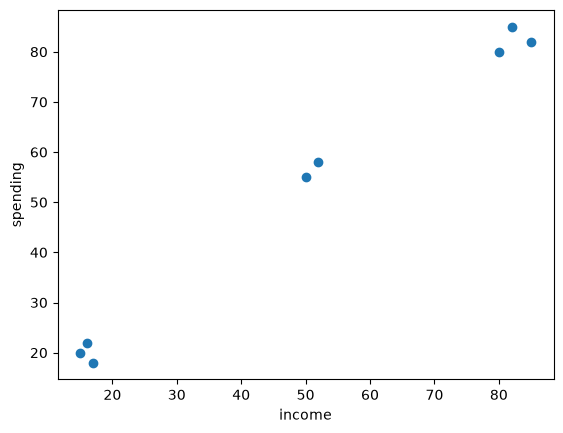

In [4]:
import matplotlib.pyplot as plt

plt.scatter(
    df["Income"],
    df["Spending"]
    
)

plt.xlabel("income")
plt.ylabel("spending")
plt.show()

In [6]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

x = sc.fit_transform(df)

In [7]:
x

array([[-1.20349499, -1.19715289],
       [-1.16873701, -1.12348194],
       [-1.13397903, -1.27082383],
       [ 0.01303424,  0.09208868],
       [ 0.0825502 ,  0.2025951 ],
       [ 1.05577358,  1.01297552],
       [ 1.12528954,  1.19715289],
       [ 1.22956347,  1.08664647]])

# create a dendogram

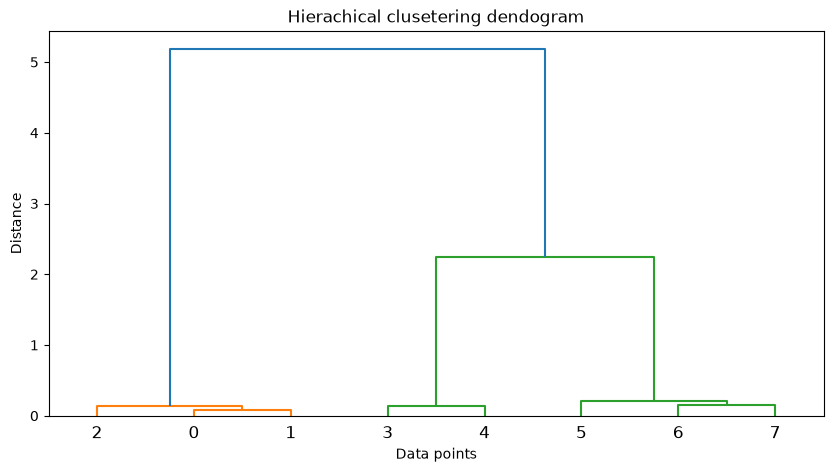

In [21]:
from scipy.cluster.hierarchy import dendrogram, linkage

z = linkage(x, method = "ward")

dendrogram(z)

plt.figure(figsize = (10,5))
plt.xlabel("Data points")
plt.ylabel("Distance")
plt.title("Hierachical clusetering dendogram")
plt.show()

# Model

In [22]:
from sklearn.cluster import AgglomerativeClustering

model = AgglomerativeClustering(n_clusters=2, linkage="ward")

labels = model.fit_predict(x)
print(labels)

[1 1 1 0 0 0 0 0]


In [23]:
df["clusters"] = labels

In [24]:
df

,Income,Spending,clusters
0,15,20,1
1,16,22,1
2,17,18,1
3,50,55,0
4,52,58,0
5,80,80,0
6,82,85,0
7,85,82,0


Text(0.5, 1.0, 'Custermer Segmentation')

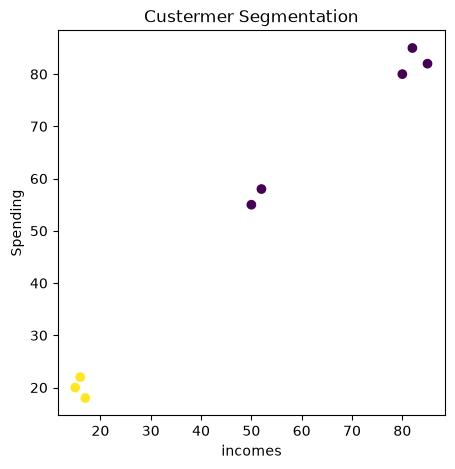

In [25]:
plt.figure(figsize = (5,5))

plt.scatter(
    df["Income"],
    df["Spending"],
    c = df["clusters"]
)


plt.xlabel("incomes")
plt.ylabel("Spending")
plt.title("Custermer Segmentation")

# what is diff between kMean and hirarchical clusetering

KMeans:
- Centroid base
- requries k befor hand
- iterative optimization


Hirearchical 
- Hierarchy based
- dendogram help explore cluster count
- progressive merging/division
- userful for hierachivcal releationship


k-mean says:

Tell me k

hierarchical clusetering:

    i'll show you the hierarchy and u can decide where to cut it

# Hierarchical Clustering: Key Interview Questions & Answers

---

## 1. Conceptual & Basics

### Q1: What is Hierarchical Clustering, and how does it differ from K-Means?
* **Hierarchical Clustering** creates a tree of clusters (dendrogram) by either iteratively merging small clusters or splitting large ones. It does not require specifying the number of clusters ($k$) upfront.
* **K-Means** requires pre-specifying $k$, assigns every point to one of $k$ centroids, and scales much better to large datasets.

---

### Q2: What is the difference between Agglomerative and Divisive Hierarchical Clustering?
* **Agglomerative (Bottom-Up):** Starts with every data point in its own cluster and merges the closest pairs iteratively until all points belong to a single root cluster.
* **Divisive (Top-Down):** Starts with all data points in one cluster and recursively splits them into smaller sub-clusters until every point is in its own cluster.

---

### Q3: What is a Dendrogram, and how do you read it to find the optimal number of clusters?
* A **dendrogram** is a tree diagram that illustrates the sequence of merges or splits.
* The vertical axis represents the **distance or dissimilarity** at which two clusters are merged.
* **How to find $k$:** Look for the longest vertical lines that do not cross any horizontal merge line. Drawing a horizontal cut across this gap yields the optimal number of clusters based on the number of vertical intersections.

---

## 2. Distance & Linkage Criteria

### Q4: Explain the four primary Linkage Criteria used in Hierarchical Clustering.
* **Single Linkage:** Measures the *minimum* distance between any single point in Cluster A and any single point in Cluster B.
* **Complete Linkage:** Measures the *maximum* distance between any point in Cluster A and any point in Cluster B (tends to form compact, spherical clusters).
* **Average Linkage:** Calculates the *average* distance between all pairs of points across Cluster A and Cluster B.
* **Ward’s Linkage:** Minimizes the total *within-cluster variance* increase when merging two clusters (most commonly used in real-world applications).

---

### Q5: What is the "Chaining Effect" in Single Linkage, and why is it a problem?
* The **chaining effect** occurs when single linkage merges clusters based on individual close pairs, leading to long, continuous, ribbon-like clusters rather than distinct, compact groups.

---

### Q6: Which distance metrics can be used, and why is Feature Scaling important?
* Common metrics include **Euclidean**, **Manhattan**, and **Cosine** distance.
* **Feature Scaling (Standardization/Normalization):** Crucial because distance metrics are sensitive to feature scales. Unscaled features with larger ranges will disproportionately dominate the cluster distance calculations.

---

## 3. Practical Trade-offs & Advanced Topics

### Q7: What are the Time and Space Complexities of Agglomerative Clustering?
* **Time Complexity:** $O(n^3)$ in standard implementations; can be optimized to $O(n^2 \log n)$ or $O(n^2)$ using priority queues.
* **Space Complexity:** $O(n^2)$ because it must store an $n \times n$ proximity/distance matrix.
* **Takeaway:** The $O(n^2)$ space requirements make it unsuitable for massive datasets ($n > 100,000$).

---

### Q8: How do outliers affect Hierarchical Clustering?
* Outliers can remain in tiny single-element clusters until the final stages of execution or severely distort distance computations (especially in Complete and Ward’s linkage).

---

### Q9: How do you evaluate the quality of a Dendrogram using Cophenetic Correlation?
* **Cophenetic Distance:** The height on the dendrogram where two points are first joined into the same cluster.
* **Cophenetic Correlation Coefficient:** Measures the Pearson correlation between actual pairwise distances in the original space and their cophenetic distances in the dendrogram. A score close to **1.0** indicates the dendrogram accurately preserves original point relationships.

---

### Q10: Can you update an existing Hierarchical Clustering model with new incoming data points easily?
* **No.** Adding new data points requires recomputing the pairwise distance matrix and rebuilding the dendrogram from scratch. It is not suitable for streaming or real-time data environments.